# Explore an Open-ST tumor microenvironment

Compare curated identities and archived scPISCES/scGPT predictions
across 39,167 cells from one metastatic human lymph-node section.
All figures below are saved in the notebook; rerunning needs only a CPU.

## 1. Load the spatial example

The bundled table contains cell identities and spatial coordinates,
not expression matrices or model weights. Labels are matched by exact
cell ID. Coordinates are used for these plots, not as annotation inputs.

In [1]:
%matplotlib inline
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "tutorials/data").is_dir())
sys.path.insert(0, str(ROOT / "tutorials"))
from _common import configure_plots, clean_map, save_figure, program_cmap
configure_plots()
DATA, OUTPUT = ROOT / "tutorials/data", ROOT / "tutorials/outputs"
cells = pd.read_csv(DATA / "openst_cells.csv.gz", dtype={"cell_id": str})
expected = json.loads((DATA / "openst_expected_metrics.json").read_text())
assert cells.cell_id.is_unique and len(cells) == expected["n_cells"]
assert np.isfinite(cells[["spatial_x", "spatial_y"]]).all().all()
metrics = pd.DataFrame({method: {
    "Accuracy": accuracy_score(cells.annotated_cell_type, cells[method]),
    "Macro-F1": f1_score(cells.annotated_cell_type, cells[method], average="macro", zero_division=0),
} for method in ["scGPT", "scPISCES"]}).T
for method in metrics.index:
    np.testing.assert_allclose(metrics.loc[method],
        [expected["methods"][method]["accuracy"], expected["methods"][method]["macro_f1"]])
display(metrics.style.format("{:.3f}"))

,Accuracy,Macro-F1
scGPT,0.672,0.334
scPISCES,0.747,0.507


## 2. Compare whole-section identities

All three panels show the same cells at the same coordinates and
use the same palette. The broad tumor region and surrounding immune
and stromal populations can be inspected without embedding distortion.

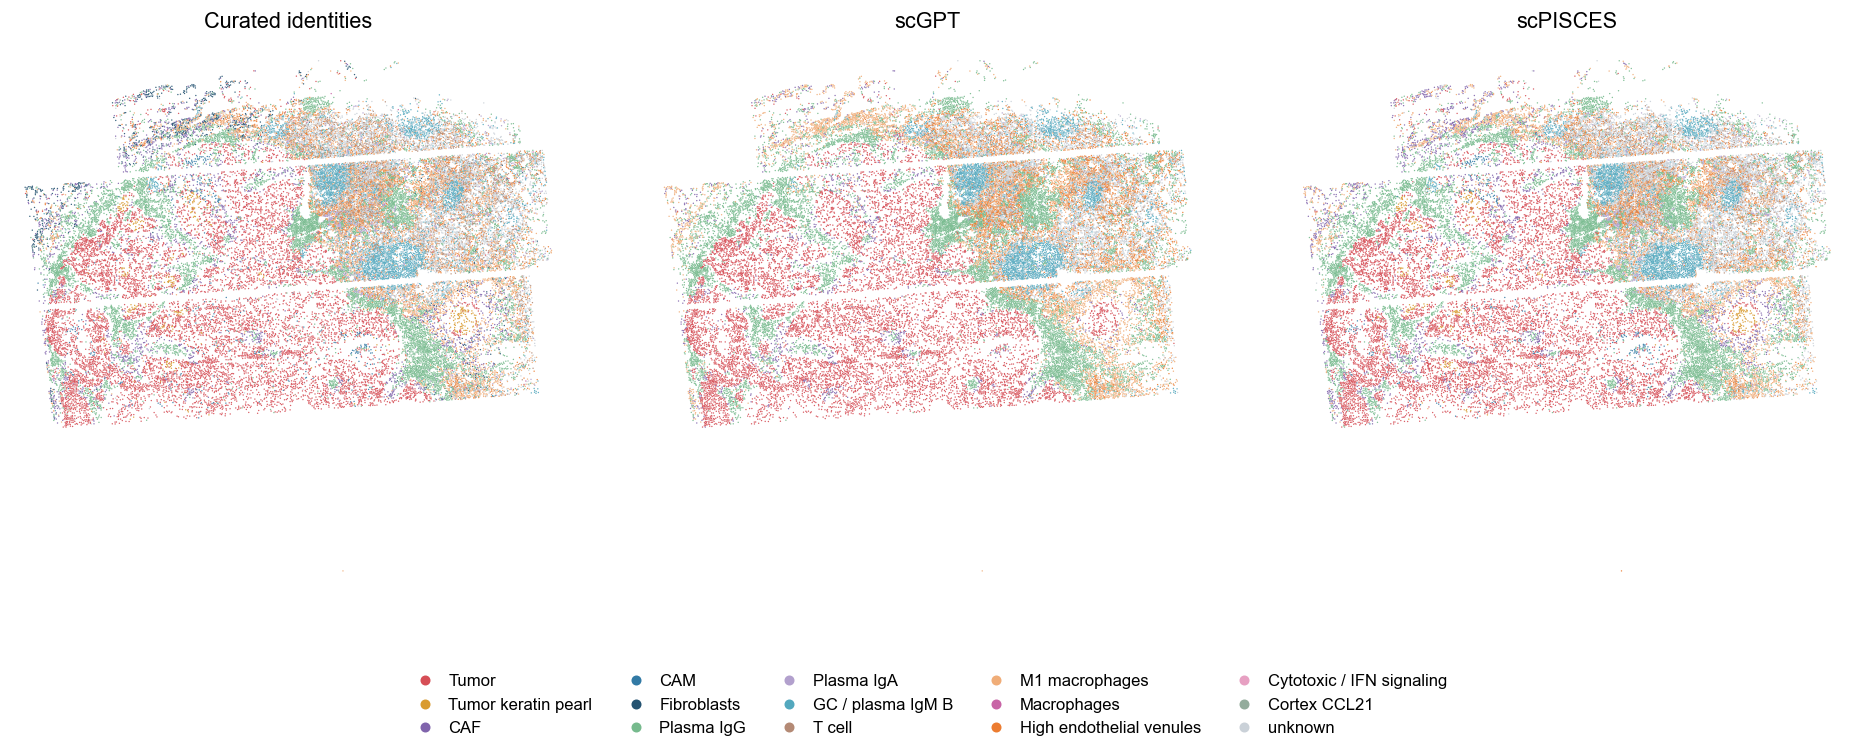

In [2]:
palette = {
    "Tumor": "#D64E56", "Tumor_Keratin_Pearl": "#D99B30",
    "CAF": "#8064AC", "CAM": "#327AA5", "Fibroblasts": "#245371",
    "Plasma_IgG": "#76BA8D", "Plasma_IgA": "#B2A0CD",
    "Germinal_Center_Plasma_IgM_B_cell": "#53A8BE", "T_cell": "#B48A75",
    "M1_macrophages": "#F0AD78", "Macrophages": "#C864A6",
    "High_Endothelial_Venules": "#EC7C30", "Cytotoxic_IFN_signaling": "#E7A0C2",
    "Cortex_CCL21": "#93AC9C", "unknown": "#CAD1D8",
}
labels = {name: name.replace("_", " ") for name in palette}
labels.update({"Tumor_Keratin_Pearl": "Tumor keratin pearl",
               "Germinal_Center_Plasma_IgM_B_cell": "GC / plasma IgM B",
               "High_Endothelial_Venules": "High endothelial venules",
               "Cytotoxic_IFN_signaling": "Cytotoxic / IFN signaling"})
methods = ["annotated_cell_type", "scGPT", "scPISCES"]
all_labels = set().union(*(set(cells[column]) for column in methods))
assert all_labels <= set(palette)
xy = cells[["spatial_x", "spatial_y"]].to_numpy()
lower, upper = xy.min(axis=0), xy.max(axis=0)
margin = (upper - lower) * 0.025

def tissue_axes(ax):
    ax.set_xlim(lower[0] - margin[0], upper[0] + margin[0])
    ax.set_ylim(upper[1] + margin[1], lower[1] - margin[1])
    clean_map(ax)

fig, axes = plt.subplots(1, 3, figsize=(16, 6.2))
for ax, column in zip(axes, methods):
    ax.scatter(*xy.T, c=cells[column].map(palette), s=0.7, linewidths=0, alpha=0.9)
    title = "Curated identities" if column == "annotated_cell_type" else column
    ax.set_title(title, pad=12)
    tissue_axes(ax)
handles = [Line2D([], [], marker="o", linestyle="", color=color,
                  markersize=5, label=labels[name]) for name, color in palette.items()]
fig.legend(handles=handles, loc="lower center", ncol=5, fontsize=10,
           columnspacing=1.6, handletextpad=0.4)
fig.subplots_adjust(left=0.01, right=0.99, top=0.94, bottom=0.22, wspace=0.06)
save_figure(fig, OUTPUT, "openst_tissue_annotation")
plt.show()

## 3. Inspect tumor and stromal compartments

Change `FOCUS_TYPES` to explore other populations. Colored points
show the selected label; light gray points retain the tissue outline.
Recall is calculated against curated identities for that population.
CAF and CAM are the source dataset's annotation labels.

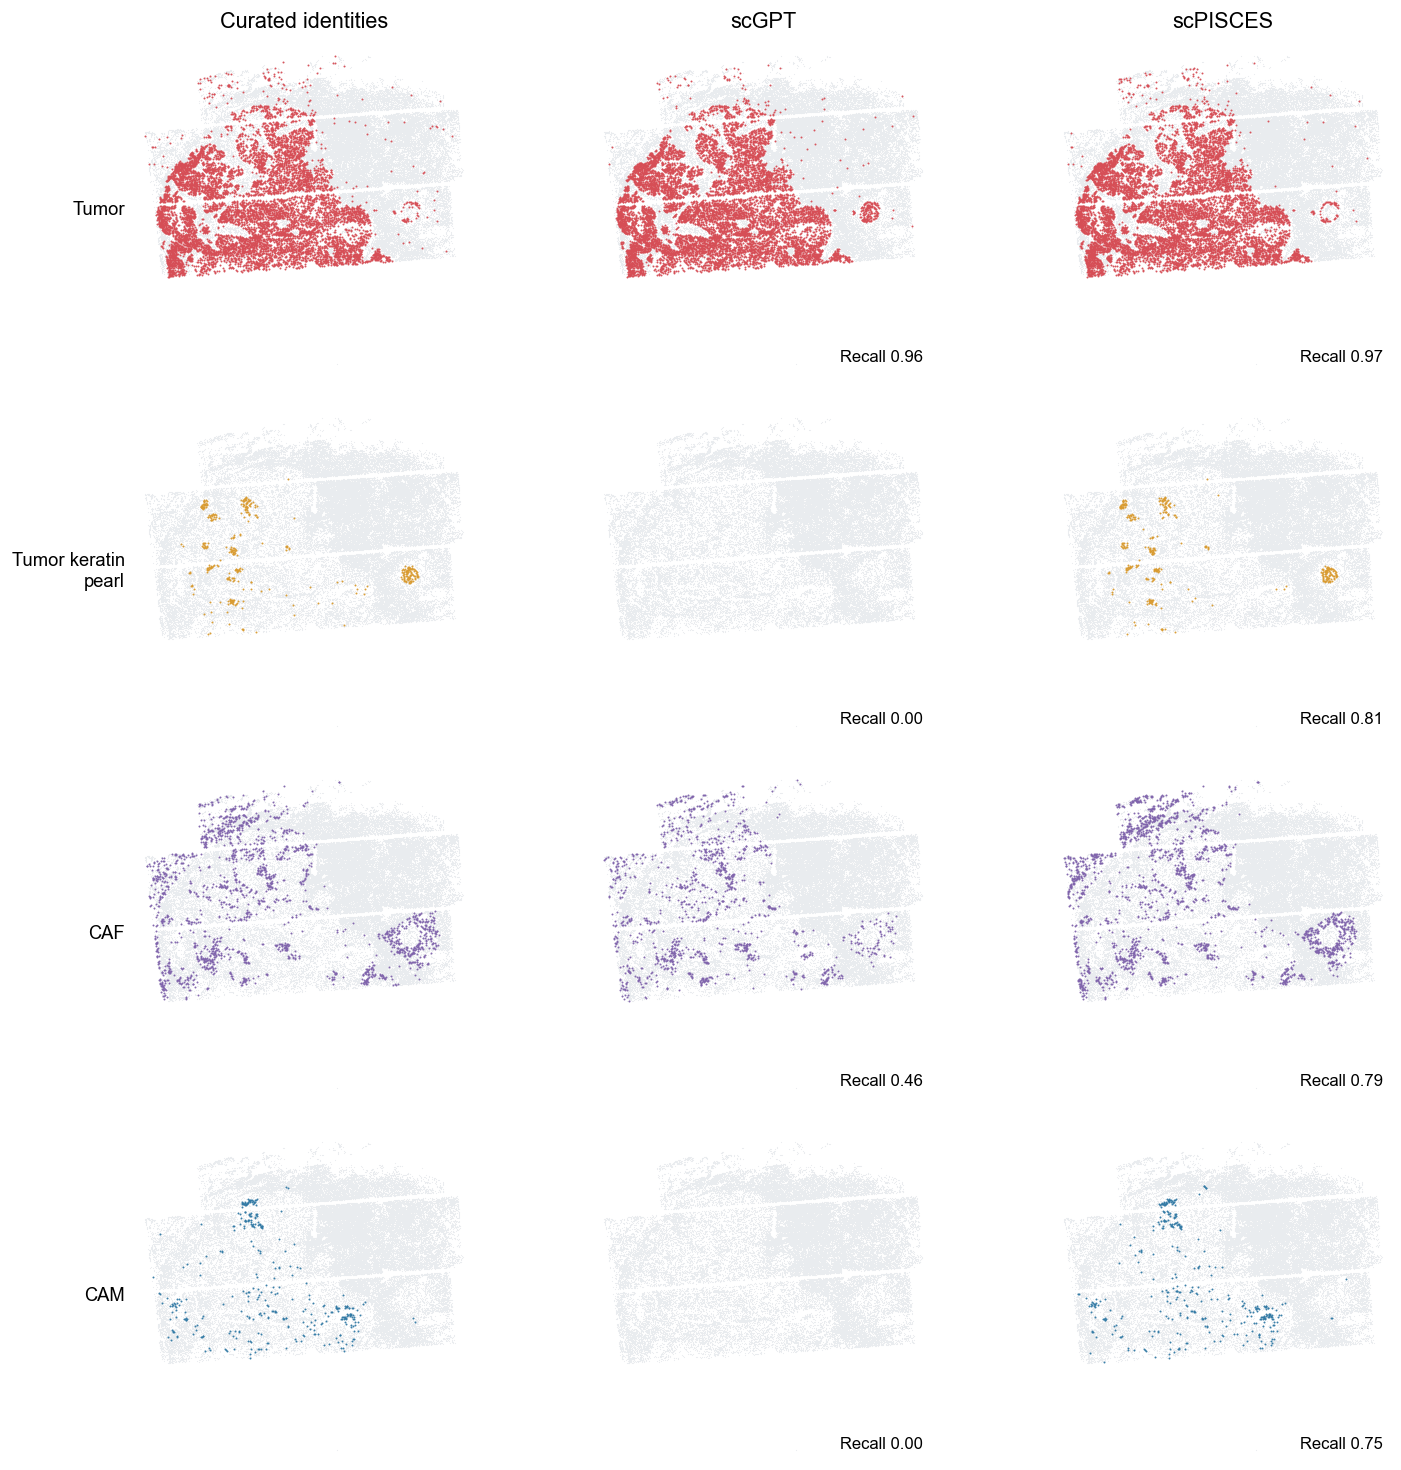

In [3]:
FOCUS_TYPES = ["Tumor", "Tumor_Keratin_Pearl", "CAF", "CAM"]
fig, axes = plt.subplots(len(FOCUS_TYPES), 3, figsize=(13.5, 12.5))
for row, cell_type in enumerate(FOCUS_TYPES):
    truth = cells.annotated_cell_type.eq(cell_type).to_numpy()
    for col, column in enumerate(methods):
        ax = axes[row, col]
        mask = cells[column].eq(cell_type).to_numpy()
        ax.scatter(*xy.T, color="#E9ECEF", s=0.45, linewidths=0)
        ax.scatter(*xy[mask].T, color=palette[cell_type], s=1.4, linewidths=0, alpha=0.95)
        tissue_axes(ax)
        if row == 0:
            ax.set_title("Curated identities" if col == 0 else column, pad=12)
        if col == 0:
            ax.text(-0.035, 0.5, labels[cell_type].replace(" keratin ", " keratin\n"),
                    ha="right", va="center", transform=ax.transAxes, fontsize=11)
        else:
            recall = np.sum(mask & truth) / truth.sum()
            ax.text(0.98, 0.02, f"Recall {recall:.2f}", ha="right", va="bottom",
                    transform=ax.transAxes, fontsize=10,
                    bbox={"facecolor": "white", "edgecolor": "none", "pad": 2})
fig.subplots_adjust(left=0.15, right=0.99, top=0.96, bottom=0.02, wspace=0.04, hspace=0.12)
save_figure(fig, OUTPUT, "openst_tumor_stroma_facets")
plt.show()

## 4. See where curated populations are assigned

Each row includes **all** cells with one curated identity. Dot area
and color encode the fraction assigned to each predicted category;
each row sums to 100%. Predictions outside the four selected labels
are pooled into Other. Diagonal entries therefore represent recall,
not precision. No cells are selected by prediction correctness.

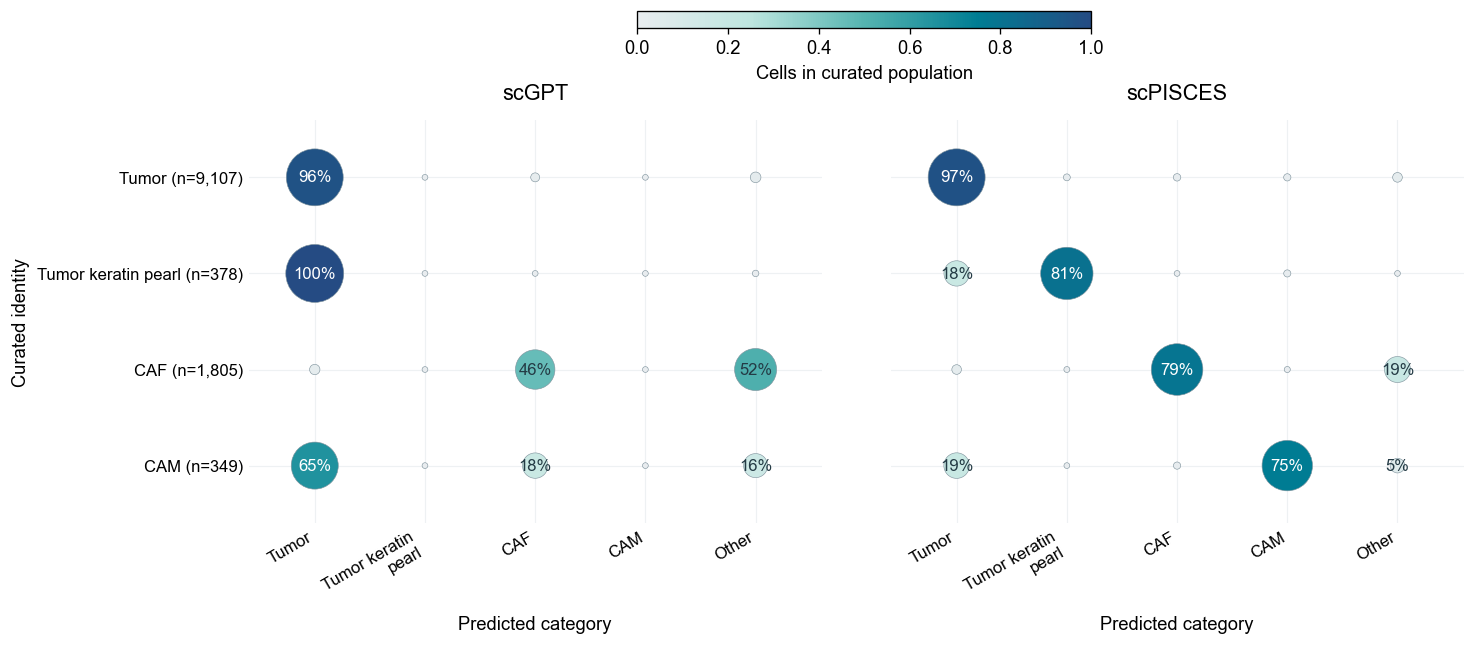

In [4]:
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

CORE_TYPES = ["Tumor", "Tumor_Keratin_Pearl", "CAF", "CAM"]
categories = CORE_TYPES + ["Other"]
fractions = {}
truth = cells.annotated_cell_type
for method in ["scGPT", "scPISCES"]:
    assigned = cells[method].where(cells[method].isin(CORE_TYPES), "Other")
    counts = pd.crosstab(truth, assigned).reindex(index=CORE_TYPES, columns=categories, fill_value=0)
    fractions[method] = counts.div(counts.sum(axis=1), axis=0)
    np.testing.assert_allclose(fractions[method].sum(axis=1), 1)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.9))
xx, yy = np.meshgrid(np.arange(len(categories)), np.arange(len(CORE_TYPES)))
cmap, norm = program_cmap(), Normalize(0, 1)
for ax, method in zip(axes, ["scGPT", "scPISCES"]):
    matrix = fractions[method].to_numpy()
    ax.scatter(xx.ravel(), yy.ravel(), s=12 + 1200*matrix.ravel(), c=matrix.ravel(),
               cmap=cmap, norm=norm, edgecolors="#7E929C", linewidths=0.35)
    for (i, j), value in np.ndenumerate(matrix):
        if value >= 0.05:
            ax.text(j, i, f"{value:.0%}", ha="center", va="center", fontsize=10,
                    color="white" if value > 0.6 else "#243B45")
    ax.set_xticks(range(len(categories)), [labels.get(x, x).replace(" keratin ", " keratin\n") for x in categories],
                  rotation=30, ha="right")
    ax.set_yticks(range(len(CORE_TYPES)),
        [f"{labels[x]} (n={truth.eq(x).sum():,})" for x in CORE_TYPES] if method == "scGPT" else [""]*4)
    ax.set_xlim(-0.6, len(categories)-0.4)
    ax.set_ylim(len(CORE_TYPES)-0.4, -0.6)
    ax.tick_params(length=0, labelsize=10)
    ax.grid(color="#EEF1F3", linewidth=0.7)
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_title(method, pad=12)
    ax.set_xlabel("Predicted category")
axes[0].set_ylabel("Curated identity")
fig.subplots_adjust(left=0.23, right=0.98, top=0.80, bottom=0.23, wspace=0.12)
legend_ax = fig.add_axes([0.47, 0.93, 0.28, 0.023])
fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), cax=legend_ax,
             orientation="horizontal", label="Cells in curated population")
save_figure(fig, OUTPUT, "openst_label_correspondence")
plt.show()

## Next steps

Explore another population by changing the lists above. PNG and
editable-text SVG figures are written to `tutorials/outputs/`.
This example describes one metastatic lymph-node section; it does
not establish generalization across cancer types. Live annotation
with your own compatible model assets is shown in the
[MERFISH annotation tutorial](Tutorial_Annotation_MERFISH.ipynb).